<a href="https://colab.research.google.com/github/mehmoodanas/Day-1/blob/main/Day_2_Supervised_learning_practical_tasks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 2 - Supervised learning practical tasks
***
These tasks cover linear regression, logistic regression, decision trees, model evaluation and regularization.

## Regression models

You will use [Advertising](https://www.kaggle.com/purbar/advertising-data) Dataset. The dataset contains statistics about the sales of a product in 200 different markets, together with advertising budgets in each of these markets for different media channels: TV, radio and newspaper.
#### Your task will be to:
1. Write evaluation functions (MAE, MSE, SSE, RMSE, MAPE, R2).
2. Analyze the correlation matrix.
3. Predict sales values using linear regression.
4. Evaluate model with written statistical explanatory variables.
5. Perform cross-validation (k-fold).
6. Compare your regression model to a reduced model by removing one of the features.
7. Compare your regression model to regularization models.

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

In [1]:
import pandas as pd
import numpy as np

# Data
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_regression

# Models
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.linear_model import ElasticNet

# Model evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

### 1. Create statistical evaluation functions for regression models

#### 1.1 Create a function that calculates mean absolute error (MAE)

\begin{equation}
MAE = \frac{1}{n} \sum_{i=1}^{n} \left| y_i - \hat{y}_i\right|
\end{equation}

In [4]:
def MAE(y_test, y_pred):
    n = len(y_test)
    mae = np.sum(np.abs(y_test - y_pred)) / n
    return mae

#### 1.2 Create a function that calculates mean squared error (MSE)

\begin{equation}
MSE = \frac{1}{n}\cdot SSE
\end{equation}

\begin{equation}
SSE = \sum_{i=1}^n(y_i - \hat{y}_i)^2
\end{equation}

In [5]:
def MSE(y_test, y_pred):
    n = len(y_test)
    sse = np.sum((y_test - y_pred) ** 2)
    mse = sse / n
    return mse

#### 1.3 Create a function that calculates root mean squared error (RMSE)

\begin{equation}
RMSE = \sqrt{MSE}
\end{equation}

In [6]:
def RMSE(y_test, y_pred):
    mse = MSE(y_test, y_pred)
    rmse = np.sqrt(mse)
    return rmse

#### 1.4 Create a function that calculates mean absolute percentage error (MAPE)

\begin{equation}
MAPE = \frac{100}{n} \sum_{i=1}^n \left| \frac{y_i - \hat{y}_i}{y_i} \right|
\end{equation}

In [7]:
def MAPE(y_test, y_pred):
    n = len(y_test)
    mape = 100 / n * np.sum(np.abs((y_test - y_pred) / y_test))
    return mape

#### 1.5 Create a function that calculates coefficient of determination $R^2$ using formula

\begin{equation}
R^2 = \frac{SST-SSE}{SST}
\end{equation}

\begin{equation}
SST = \sum_{i=1}^n (y_i - \bar{y})^2
\end{equation}


In [8]:
def R2(y_test, y_pred):
    sse = np.sum((y_test - y_pred) ** 2)
    sst = np.sum((y_test - np.mean(y_test)) ** 2)
    r2 = (sst - sse) / sst
    return r2

### 2 Use Linear regression model to make predictions and evaluate it with above developed functions. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling - split the data in target variable and features.

In [24]:
data = pd.read_csv('advertising.csv')
data = data.drop(columns='Unnamed: 0')
data.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [25]:
data.isnull().sum()

,0
TV,0
Radio,0
Newspaper,0
Sales,0


In [27]:
x = data[['TV', 'Radio', 'Newspaper']]
y = data['Sales']

#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

In [29]:
corr = data.corr().round(2)
corr

,TV,Radio,Newspaper,Sales
TV,1.00,0.05,0.06,0.78
Radio,0.05,1.00,0.35,0.58
Newspaper,0.06,0.35,1.00,0.23
Sales,0.78,0.58,0.23,1.00


<Axes: >

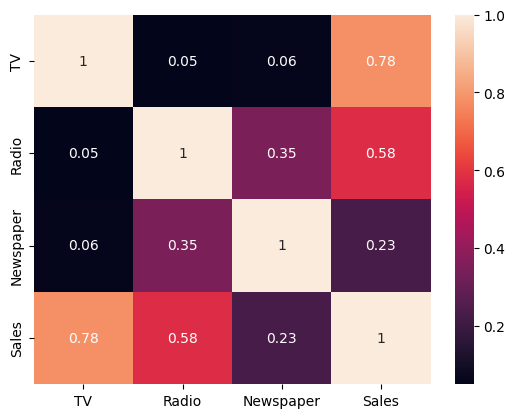

In [33]:
sns.heatmap(corr, annot=True)

Observation: Here we can see that the orange box of TV has high correlation with Sales 0.78 and it shows the strong correlation and then red box of radios 0.58 and sales shows the correlation not strong enough like TV. It means TV giving more money because of more sales and the most weak link is with newspaper 0.23.

And between the fetures we can see that radio and newspaper are little bit correlated 0.35. And TV is almost zero like almost no correlation.

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler).

In [39]:
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=17)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(134, 3) (134,) (66, 3) (66,)


#### 2.4 Fit linear regression model, generate predictions and print regression coefficients $b_0$ and $b_1$.

In [44]:
model = LinearRegression(fit_intercept=True)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

In [46]:
print(model.intercept_) # b0
print(model.coef_) # b1

14.022388059701495
[ 3.9675339   2.88155345 -0.07344038]


#### 2.5 Evaluate created model with above functions

In [48]:
print("MAE score:", MAE(y_test, y_pred).round(4))
print("MSE score:", MSE(y_test, y_pred).round(4))
print("RMSE score:", RMSE(y_test, y_pred).round(4))
print("MAPE score:", MAPE(y_test, y_pred).round(4))
print("R^2 score:", R2(y_test, y_pred).round(4))

MAE score: 1.2415
MSE score: 3.4726
RMSE score: 1.8635
MAPE score: 18.6388
R^2 score: 0.8515


#### 2.6 Perform k-fold cross-validation $(k=10)$ and print the mean $R^2$ score to get an overall performance metric.

Please use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [r2](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules) score.

In [50]:
from sklearn.model_selection import KFold, cross_val_score

k = 10
kf = KFold(n_splits=k, shuffle=True, random_state=42)

scores = cross_val_score(model, X_train_scaled, y_train, cv=kf, scoring='r2')
print("R^2 score for each fold:", scores.round(4))
print("Mean R^2 score:", round(scores.mean(),4))

R^2 score for each fold: [0.7855 0.8584 0.9237 0.9246 0.8663 0.9575 0.8903 0.8849 0.9305 0.8383]
Mean R^2 score: 0.886


#### 2.7. Drop one of the three variables (TV, Radio or Newspaper) and create another model, evaluate it and compare to the first model.

In [51]:
x2 = x.drop(columns='Newspaper')

x2_train, x2_test, y2_train, y2_test = train_test_split(
    x2, y, test_size=0.33, random_state=17)

scaler2 = StandardScaler()
x2_train_scaled = scaler2.fit_transform(x2_train)
x2_test_scaled = scaler2.transform(x2_test)

model2 = LinearRegression(fit_intercept=True)
model2.fit(x2_train_scaled, y2_train)
y2_pred = model2.predict(x2_test_scaled)

In [55]:
print("MAE score:", MAE(y2_test, y2_pred).round(4))
print("MSE score:", MSE(y2_test, y2_pred).round(4))
print("RMSE score:", RMSE(y2_test, y2_pred).round(4))
print("MAPE score:", MAPE(y2_test, y2_pred).round(4))
print("R^2 score:", R2(y2_test, y2_pred).round(4))

print("First model R^2:", R2(y_test, y_pred).round(4), " New model R^2:", R2(y2_test, y2_pred).round(4))
print("First model MSE:", MSE(y_test, y_pred).round(4), " New model MSE:", MSE(y2_test, y2_pred).round(4))

MAE score: 1.2424
MSE score: 3.4587
RMSE score: 1.8598
MAPE score: 18.5946
R^2 score: 0.8521
First model R^2: 0.8515  New model R^2: 0.8521
First model MSE: 3.4726  New model MSE: 3.4587


### 3. Use regularization models with regularization strength `alpha=1` and compare $MSE$ values with previous models.

#### 3.1 Lasso regression

In [58]:
lasso = Lasso(alpha=1)
lasso.fit(X_train_scaled, y_train)

y_pred_lasso = lasso.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred_lasso)
print("Mean Squared Error:", mse)
print("Coefficients:", lasso.coef_)

Mean Squared Error: 4.911579294712749
Coefficients: [3.0619592  1.96202634 0.        ]


#### 3.2 Ridge regression

In [59]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)

y_pred_ridge = ridge.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred_ridge)
print("Mean Squared Error:", mse)
print("Coefficients:", ridge.coef_)

Mean Squared Error: 3.476889477472239
Coefficients: [ 3.93899368  2.85996406 -0.06218255]


#### 3.3 Elastic net regression

Use any `l1_ratio` of your choice.


In [60]:
elastic_net = ElasticNet(alpha=1.0, l1_ratio=0.5)
elastic_net.fit(X_train_scaled, y_train)

y_pred_elastic = elastic_net.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred_elastic)
print("Mean Squared Error:", mse)
print("Coefficients:", elastic_net.coef_)

Mean Squared Error: 6.843883320104106
Coefficients: [2.39397459 1.68907463 0.01489489]


#### 3.4 Make conclusions

i worked on Linear regression using the advertig Dataset and calculets values of MSE, MAE, MAPE, R^2 and RMSE. The linear regression model works well. As we can see MSE is 3.4726 and its R² is 0.8515. The cross validation result is 0.886. This is close to the first result, so the model is stable.

TV is the main feature. Radio is second. Newspaper is not important because its number is almost 0 and we can also observe the heatmap.

When we removed Newspaper, the result was almost the same. The MSE was 3.4587 and the R² was 0.8512.

Ridge gave almost the same result as linear regression 3.4769. Lasso was worse MSE 4.9116. Lasso made the Newspaper number 0 which means newspaper is not important. Elastic Net was the worst MSE 6.8439.

Regularization did not make the model better. The best models are normal linear regression and the model with only TV and Radio.

## Classification models

You will use [Diabetes](https://www.kaggle.com/uciml/pima-indians-diabetes-database) dataset. The dataset includes data from 768 women with several medical predictor variables and one target variable. The classification goal is to predict whether or not the patients in the dataset have diabetes.
#### Your task will be to:
1. Write evaluation functions (Accuracy, Precision, Recall, F1).
2. Predict whether or not a patient has diabetes using Logistic regression and Decision Tree Classification models
3. Evaluate both models with written statistical explanatory variables
4. Draw ROC curve and compute AUC
5. Perform cross-validation (k-fold)
6. Analyze the results

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

### 1. Write statistical evaluation functions for classification models

#### 1.1 Create a function that calculates accuracy

\begin{equation}
Accuracy = \frac{True Positive + True Negative}{True Positive + True Negative + False Positive + False Negative}
\end{equation}

In [69]:
def Accuracy(y_test, y_pred):
    TP = np.sum((y_test == 1) & (y_pred == 1))
    TN = np.sum((y_test == 0) & (y_pred == 0))
    FP = np.sum((y_test == 0) & (y_pred == 1))
    FN = np.sum((y_test == 1) & (y_pred == 0))
    accuracy = (TP + TN) / (TP + TN + FP + FN)
    return accuracy

#### 1.2 Create a function that calculates precision

\begin{equation}
Precision = \frac{True Positive}{True Positive + False Positive}
\end{equation}

In [70]:
def Precision(y_test, y_pred):
    TP = np.sum((y_test == 1) & (y_pred == 1))
    FP = np.sum((y_test == 0) & (y_pred == 1))
    precision = TP / (TP + FP)
    return precision

#### 1.3  Create a function that calculates recall

\begin{equation}
Recall = \frac{True Positive}{True Positive + False Negative}
\end{equation}

In [71]:
def Recall(y_test, y_pred):
    TP = np.sum((y_test == 1) & (y_pred == 1))
    FN = np.sum((y_test == 1) & (y_pred == 0))
    recall = TP / (TP + FN)
    return recall

#### 1.4 Create a function that calculates $F1$ - score

\begin{equation}
F1 = 2\cdot \frac{Precision \cdot Recall}{Precision + Recall}
\end{equation}

In [72]:
def F1(y_test, y_pred):
    precision = Precision(y_test, y_pred)
    recall = Recall(y_test, y_pred)
    f1 = 2 * (precision * recall) / (precision + recall)
    return f1

### 2. Use logistic regression to make prediction and evaluate it with above developed functions. Compute ROC and compute AUC. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling. Split the data in target variable and features.

Prepare dataset to use it for modelling (you should also replace 0 values in columns `Glucose`, `BloodPressure`,`SkinThickness`,`Insulin`,`BMI` with mean values).

In [61]:
diabetes = pd.read_csv('diabetes.csv')
diabetes.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [62]:
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
diabetes[cols] = diabetes[cols].replace(0, np.nan)
diabetes[cols] = diabetes[cols].fillna(diabetes[cols].mean())

X = diabetes.drop(columns='Outcome')
y = diabetes['Outcome']
diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.00000,155.548223,33.6,0.627,50,1
1,1,85.0,66.0,29.00000,155.548223,26.6,0.351,31,0
2,8,183.0,64.0,29.15342,155.548223,23.3,0.672,32,1
3,1,89.0,66.0,23.00000,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.00000,168.000000,43.1,2.288,33,1


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

In [63]:
corr = diabetes.corr()
corr

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.127911,0.208522,0.082989,0.056027,0.021565,-0.033523,0.544341,0.221898
Glucose,0.127911,1.000000,0.218367,0.192991,0.420157,0.230941,0.137060,0.266534,0.492928
BloodPressure,0.208522,0.218367,1.000000,0.192816,0.072517,0.281268,-0.002763,0.324595,0.166074
SkinThickness,0.082989,0.192991,0.192816,1.000000,0.158139,0.542398,0.100966,0.127872,0.215299
Insulin,0.056027,0.420157,0.072517,0.158139,1.000000,0.166586,0.098634,0.136734,0.214411
BMI,0.021565,0.230941,0.281268,0.542398,0.166586,1.000000,0.153400,0.025519,0.311924
DiabetesPedigreeFunction,-0.033523,0.137060,-0.002763,0.100966,0.098634,0.153400,1.000000,0.033561,0.173844
Age,0.544341,0.266534,0.324595,0.127872,0.136734,0.025519,0.033561,1.000000,0.238356
Outcome,0.221898,0.492928,0.166074,0.215299,0.214411,0.311924,0.173844,0.238356,1.000000


<Axes: >

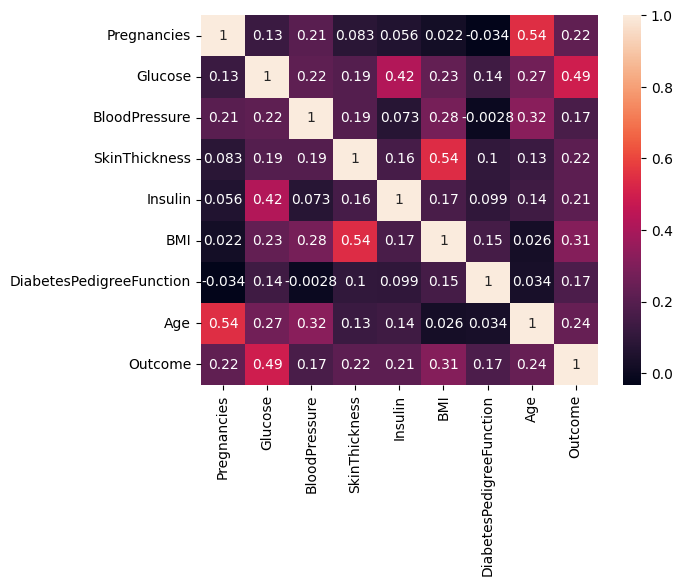

In [64]:
sns.heatmap(corr, annot=True)

Observation: As we can see Glucose has strong correlation with outcome 0.49 which mean patients with high glucose most likely to get diabetes. And then BMI, Age, pregnancy with values 0.31, 0.24, 0.22 respectively also have positive correlation with outcome and blood pressure and DiabetesPedigreeFunction	have the weakest corelation with outcome.
If we talk between the features then we can see Age and Pregnancy is strongly correlated then other features 0.54 alongside BMI and Skin Thickness are also correlated 0.54 and then Glucose and Insulin are 0.42

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

In [65]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=17)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(514, 8) (514,) (254, 8) (254,)


#### 2.4 Fit logistic regression model, generate predictions

In [66]:
logreg = LogisticRegression()
logreg.fit(X_train_scaled, y_train)

y_pred_log = logreg.predict(X_test_scaled)
y_pred_log[:10]

array([0, 1, 0, 0, 0, 0, 0, 1, 1, 1])

#### 2.5 Create a confusion matrix and evaluate created model with above functions

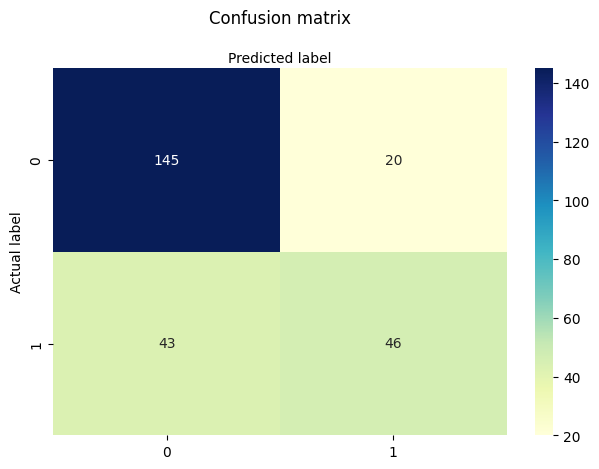

In [67]:
cnf_matrix = confusion_matrix(y_test, y_pred_log)

class_names = [0, 1]
fig, ax = plt.subplots()
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu", fmt='g',
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.xaxis.set_label_position("top")
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()

In [73]:
print("Accuracy:", Accuracy(y_test, y_pred_log))
print("Precision:", Precision(y_test, y_pred_log))
print("Recall:", Recall(y_test, y_pred_log))
print("F1 score:", F1(y_test, y_pred_log))

Accuracy: 0.7519685039370079
Precision: 0.696969696969697
Recall: 0.5168539325842697
F1 score: 0.5935483870967742


#### 2.6 Draw a ROC curve and compute Area Under the Curve (AUC)

You can use [roc_auc_score](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html) and [RocCurveDisplay.from_predictions](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html#sklearn.metrics.RocCurveDisplay.from_predictions).
Check documentation for examples.
For roc_auc_score use predicted probabilities (`predict_proba`), not predicted values. This will align your AUC and ROC curve values.

`predict_proba()` method returns a two-dimensional array. For each instance the predicted class is the class with the maximum probability. To calculate AUC correctly, you need the probability of the positive class (second column, `[:, 1]`).

AUC: 0.8311201906707525


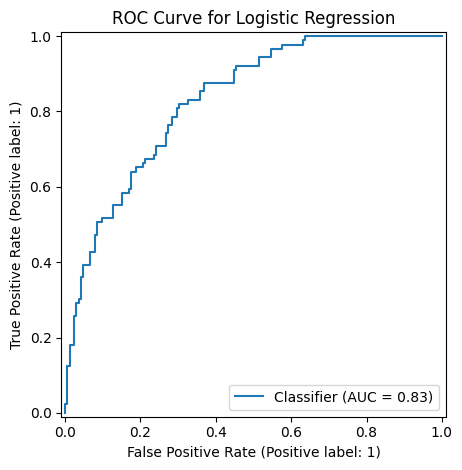

In [76]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

y_prob_log = logreg.predict_proba(X_test_scaled)[:,1]

auc = roc_auc_score(y_test, y_prob_log)
print(f'AUC: {auc}')

disp = RocCurveDisplay.from_predictions(y_test, y_prob_log)
disp.ax_.set_title("ROC Curve for Logistic Regression")
disp.figure_.tight_layout()

#### 2.7 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

Use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [accuracy](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules). Feed your scaled X train and y train data.

In [77]:
k = 10
kf = KFold(n_splits=k, shuffle=True, random_state=42)

scores = cross_val_score(logreg, X_train_scaled, y_train, cv=kf, scoring='accuracy')
print("Mean accuracy:", scores.mean())

Mean accuracy: 0.7645173453996984


### 3. Use Decision tree classification model to make predictions and evaluate it with above developed functions. Draw ROC curve and compute AUC. Perform k-fold cross-validation.

#### 3.1 Create classification tree object, fit model and generate predictions

In [78]:
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train_scaled, y_train)

y_pred_clf = clf.predict(X_test_scaled)
y_pred_clf[:10]

array([0, 1, 0, 0, 0, 0, 0, 1, 1, 1])

#### 3.2 Evaluate created model with above functions

In [79]:
print("Accuracy:", Accuracy(y_test, y_pred_clf))
print("Precision:", Precision(y_test, y_pred_clf))
print("Recall:", Recall(y_test, y_pred_clf))
print("F1 score:", F1(y_test, y_pred_clf))

Accuracy: 0.7716535433070866
Precision: 0.6703296703296703
Recall: 0.6853932584269663
F1 score: 0.6777777777777777


#### 3.3 Draw a ROC curve and compute Area Under the Curve (AUC)

AUC: 0.7517875383043923


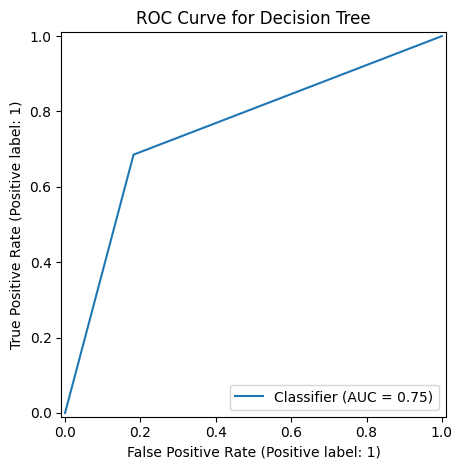

In [80]:
y_prob_clf = clf.predict_proba(X_test_scaled)[:,1]

auc = roc_auc_score(y_test, y_prob_clf)
print(f'AUC: {auc}')

disp = RocCurveDisplay.from_predictions(y_test, y_prob_clf)
disp.ax_.set_title("ROC Curve for Decision Tree")
disp.figure_.tight_layout()

#### 3.4 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

In [81]:
scores = cross_val_score(clf, X_train_scaled, y_train, cv=kf, scoring='accuracy')
print("Mean accuracy:", scores.mean())

Mean accuracy: 0.6863876319758673


#### 3.5 Make conclusions

Here's a simpler version. It mostly says what was done and what the numbers show, without sounding like an expert:

> First we made logistic regression model and checked it on the test data. The accuracy is 0.7520, so it is correct for around 75% of patients. The precision is 0.6970, recall is 0.5169 and F1 score is 0.5935. The AUC is 0.8311. After that we did cross validation and the mean accuracy is 0.7645, which is close to the test accuracy.
>
> In the confusion matrix we can see the model predicted 145 patients correct as no diabetes and 46 patients correct as diabetes. But it also missed 43 patients who have diabetes, so the recall is not very high.
>
> Then we made decision tree model and did the same steps. The accuracy is 0.7717, precision is 0.6703, recall is 0.6854 and F1 score is 0.6778. So on the test data the tree got a bit higher accuracy and recall than logistic regression, and it missed only 28 patients.
>
> But the AUC of the tree is 0.7518 and the cross validation accuracy is 0.6864, and these are lower than logistic regression. So the tree did better on the test data, but in cross validation it was lower.
>
> So both models have some good and some weak points. Logistic regression has higher AUC and cross validation accuracy, and decision tree has higher accuracy and recall on the test data.